# Water Quality Prediction Using Machine Learning

This project aims to predict whether water is safe for drinking based on its physicochemical properties using Machine Learning algorithms. Three classification algorithms will be trained and evaluated to compare their performance and identify the most effective model for water potability prediction.

# 1. Importing library

**Purpose:** Import the libraries needed for data analysis, visualization, preprocessing, model training, and evaluation.

In [2]:
# 1. Data Manipulation & Analysis
import pandas as pd
import numpy as np
# 2. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# 3. Statistical Analysis
from scipy import stats
# 4. Data Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
# 5. Data Splitting & Cross Validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)
# 6. Machine Learning Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
# 7. Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
# 8. Feature Importance
from sklearn.inspection import permutation_importance
# 9. Save & Load Model
import joblib


# 2.Loading data 

**Purpose:** Load the water quality dataset into a Pandas DataFrame for analysis.

In [3]:
df = pd.read_csv("Datasets/Water Quality Prediction/water_potability.csv")

## View top 5 row

In [7]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


# 3.Exploratory Data Analysis (EDA)

## Dataset detail

**What we check:** The dataset has 3,276 samples, 9 input features, and 1 target column (`Potability`). `df.info()` shows data types and non-missing counts.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


## check balance

**Class distribution:** `0 = Not Potable` (60.99%) and `1 = Potable` (39.01%). The classes are not evenly balanced.

In [9]:
# Number of samples in each class
print("Class Counts:")
print(df["Potability"].value_counts(dropna=False))

# Percentage of each class
print("\nClass Percentages:")
print(df["Potability"].value_counts(normalize=True, dropna=False) * 100)


Class Counts:
Potability
0    1998
1    1278
Name: count, dtype: int64

Class Percentages:
Potability
0    60.989011
1    39.010989
Name: proportion, dtype: float64


## check missing value

**Missing data:** 1,265 rows contain at least one missing value. The affected features are `ph`, `Sulfate`, and `Trihalomethanes`.

In [4]:
print("Dataset Shape:", df.shape)
print("Rows with missing values:", df.isnull().any(axis=1).sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMissing Percentage:")
print((df.isnull().mean() * 100).round(2))

Dataset Shape: (3276, 10)
Rows with missing values: 1265

Missing Values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Missing Percentage:
ph                 14.99
Hardness            0.00
Solids              0.00
Chloramines         0.00
Sulfate            23.84
Conductivity        0.00
Organic_carbon      0.00
Trihalomethanes     4.95
Turbidity           0.00
Potability          0.00
dtype: float64


## Outliers detection

**Outliers:** The IQR method flags unusually high or low values in each feature. This step detects and counts outliers; it does not remove them.

In [12]:
# Outlier Detection using IQR

features = df.drop(columns=["Potability"])

Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (features < lower_bound) |
    (features > upper_bound)
)

outlier_summary = pd.DataFrame({
    "Outlier Count": outliers.sum(),
    "Outlier Percentage": (
        outliers.mean() * 100
    ).round(2)
})

print(outlier_summary)


                 Outlier Count  Outlier Percentage
ph                          46                1.40
Hardness                    83                2.53
Solids                      47                1.43
Chloramines                 61                1.86
Sulfate                     41                1.25
Conductivity                11                0.34
Organic_carbon              25                0.76
Trihalomethanes             33                1.01
Turbidity                   19                0.58


## Correlation matrix

**Correlation:** Pearson correlation measures the linear relationship between numerical variables. The heatmap makes these relationships easier to inspect.

In [13]:
corr_matrix = df.corr(method="pearson")

print("Correlation Matrix:")
print(corr_matrix.round(3))

Correlation Matrix:
                    ph  Hardness  Solids  Chloramines  Sulfate  Conductivity  \
ph               1.000     0.082  -0.089       -0.034    0.018         0.019   
Hardness         0.082     1.000  -0.047       -0.030   -0.107        -0.024   
Solids          -0.089    -0.047   1.000       -0.070   -0.172         0.014   
Chloramines     -0.034    -0.030  -0.070        1.000    0.027        -0.020   
Sulfate          0.018    -0.107  -0.172        0.027    1.000        -0.016   
Conductivity     0.019    -0.024   0.014       -0.020   -0.016         1.000   
Organic_carbon   0.044     0.004   0.010       -0.013    0.031         0.021   
Trihalomethanes  0.003    -0.013  -0.009        0.017   -0.030         0.001   
Turbidity       -0.039    -0.014   0.020        0.002   -0.011         0.006   
Potability      -0.004    -0.014   0.034        0.024   -0.024        -0.008   

                 Organic_carbon  Trihalomethanes  Turbidity  Potability  
ph                       

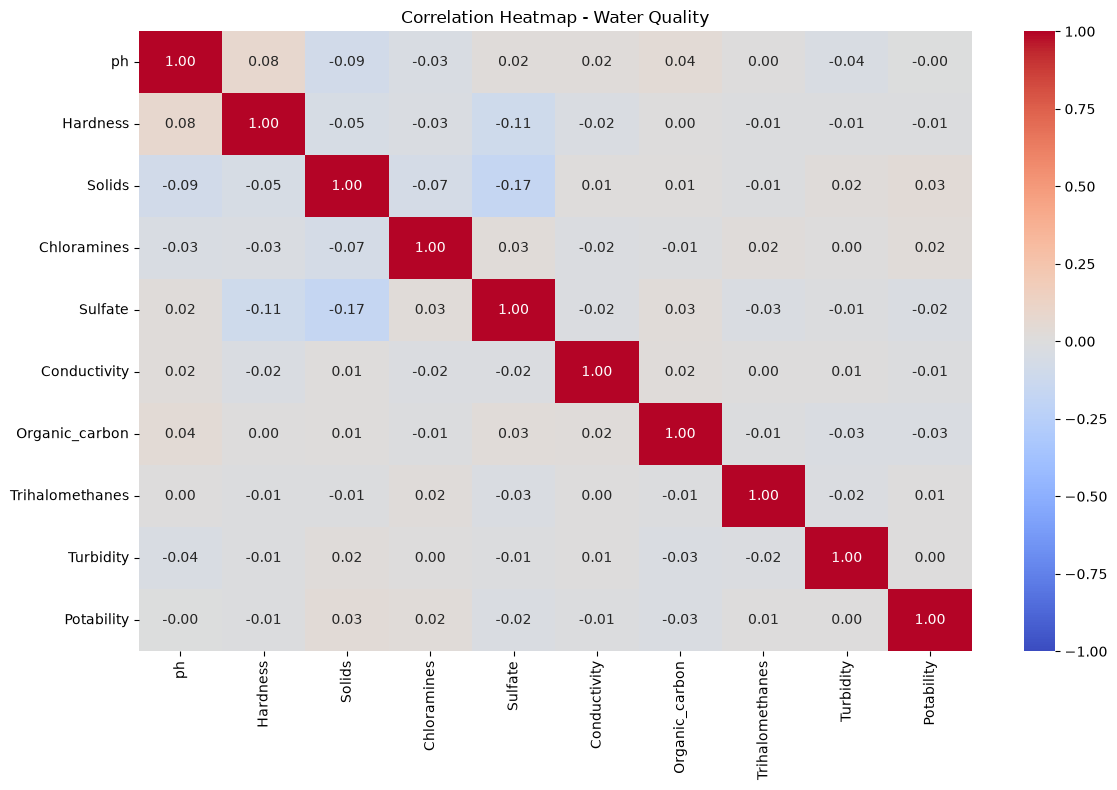

In [14]:
#correlation heatmap(visualisation )

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Water Quality")
plt.tight_layout()
plt.show()


# 4. Data preprocessing

## Train/Test dataset 
using 5 fold cross validation method

**5-Fold Cross-Validation:** Split the dataset into 5 folds. Train on 4 folds and validate on the remaining fold, repeating 5 times. `StratifiedKFold` maintains similar class proportions in each split.

In [6]:

from sklearn.model_selection import StratifiedKFold

# Separate Features and Target
X = df.drop(columns=["Potability"])
y = df["Potability"]

# Initialize Stratified 5-Fold Cross-Validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Save folds for later use
folds = list(skf.split(X, y))

# Display each fold
for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    print(f"\n========== Fold {fold} ==========")

    print("Training Samples:", len(X_train))
    print("Validation Samples:", len(X_val))

    print("\nTraining Class Distribution (%):")
    print((y_train.value_counts(normalize=True) * 100).round(2))

    print("\nValidation Class Distribution (%):")
    print((y_val.value_counts(normalize=True) * 100).round(2))



========== Fold 1 ==========
Training Samples: 2620
Validation Samples: 656

Training Class Distribution (%):
Potability
0    60.99
1    39.01
Name: proportion, dtype: float64

Validation Class Distribution (%):
Potability
0    60.98
1    39.02
Name: proportion, dtype: float64

========== Fold 2 ==========
Training Samples: 2621
Validation Samples: 655

Training Class Distribution (%):
Potability
0    60.97
1    39.03
Name: proportion, dtype: float64

Validation Class Distribution (%):
Potability
0    61.07
1    38.93
Name: proportion, dtype: float64

========== Fold 3 ==========
Training Samples: 2621
Validation Samples: 655

Training Class Distribution (%):
Potability
0    60.97
1    39.03
Name: proportion, dtype: float64

Validation Class Distribution (%):
Potability
0    61.07
1    38.93
Name: proportion, dtype: float64

========== Fold 4 ==========
Training Samples: 2621
Validation Samples: 655

Training Class Distribution (%):
Potability
0    61.01
1    38.99
Name: proportion, d

## fill missing value

**Median imputation:** Replace missing values with the median of each feature. The median is calculated from the training fold only, then applied to its validation fold to avoid data leakage.

In [7]:

processed_folds = []

for iteration, (train_idx, val_idx) in enumerate(folds, start=1):

    # Get training and validation data
    X_train = X.iloc[train_idx].copy()
    X_val = X.iloc[val_idx].copy()

    y_train = y.iloc[train_idx].copy()
    y_val = y.iloc[val_idx].copy()

    # Median Imputation
    imputer = SimpleImputer(strategy="median")

    X_train_imputed = pd.DataFrame(
        imputer.fit_transform(X_train),
        columns=X.columns,
        index=X_train.index
    )

    X_val_imputed = pd.DataFrame(
        imputer.transform(X_val),
        columns=X.columns,
        index=X_val.index
    )

    # Save processed data
    processed_folds.append({
        "iteration": iteration,
        "X_train": X_train_imputed,
        "X_val": X_val_imputed,
        "y_train": y_train,
        "y_val": y_val
    })

    print(f"\n--- Iteration {iteration} ---")
    print("Train Missing:",
          X_train_imputed.isnull().sum().sum())
    print("Validation Missing:",
          X_val_imputed.isnull().sum().sum())

    print("Medians used:")
    medians = pd.Series(
        imputer.statistics_, index=X.columns
    )
    print(medians[
        ["ph", "Sulfate", "Trihalomethanes"]
    ].round(3))



--- Iteration 1 ---
Train Missing: 0
Validation Missing: 0
Medians used:
ph                   7.026
Sulfate            333.062
Trihalomethanes     66.275
dtype: float64

--- Iteration 2 ---
Train Missing: 0
Validation Missing: 0
Medians used:
ph                   7.044
Sulfate            332.236
Trihalomethanes     66.639
dtype: float64

--- Iteration 3 ---
Train Missing: 0
Validation Missing: 0
Medians used:
ph                   7.037
Sulfate            333.271
Trihalomethanes     66.482
dtype: float64

--- Iteration 4 ---
Train Missing: 0
Validation Missing: 0
Medians used:
ph                   7.040
Sulfate            333.027
Trihalomethanes     66.609
dtype: float64

--- Iteration 5 ---
Train Missing: 0
Validation Missing: 0
Medians used:
ph                   7.032
Sulfate            333.483
Trihalomethanes     67.009
dtype: float64


## feature scaling 

**Feature scaling:** `StandardScaler` standardizes input features using the training fold’s mean and standard deviation. It is applied to Logistic Regression in this experiment.

In [8]:

scaled_iterations = []

for iteration, data in enumerate(processed_folds, start=1):

    X_train = data["X_train"]
    X_val = data["X_val"]

    # Initialize StandardScaler
    scaler = StandardScaler()

    # Fit and transform training data
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train),
        columns=X_train.columns,
        index=X_train.index
    )

    # Transform validation using training statistics
    X_val_scaled = pd.DataFrame(
        scaler.transform(X_val),
        columns=X_val.columns,
        index=X_val.index
    )

    # Save scaled data for Logistic Regression
    scaled_iterations.append({
        "iteration": iteration,
        "X_train": X_train_scaled,
        "X_val": X_val_scaled,
        "y_train": data["y_train"],
        "y_val": data["y_val"]
    })

    print(f"\n--- Iteration {iteration} ---")

    print("Training Mean:")
    print(X_train_scaled.mean().round(3))

    print("\nTraining Standard Deviation:")
    print(X_train_scaled.std(ddof=0).round(3))



--- Iteration 1 ---
Training Mean:
ph                 0.0
Hardness           0.0
Solids            -0.0
Chloramines       -0.0
Sulfate            0.0
Conductivity       0.0
Organic_carbon     0.0
Trihalomethanes   -0.0
Turbidity          0.0
dtype: float64

Training Standard Deviation:
ph                 1.0
Hardness           1.0
Solids             1.0
Chloramines        1.0
Sulfate            1.0
Conductivity       1.0
Organic_carbon     1.0
Trihalomethanes    1.0
Turbidity          1.0
dtype: float64

--- Iteration 2 ---
Training Mean:
ph                 0.0
Hardness           0.0
Solids            -0.0
Chloramines        0.0
Sulfate            0.0
Conductivity       0.0
Organic_carbon    -0.0
Trihalomethanes   -0.0
Turbidity          0.0
dtype: float64

Training Standard Deviation:
ph                 1.0
Hardness           1.0
Solids             1.0
Chloramines        1.0
Sulfate            1.0
Conductivity       1.0
Organic_carbon     1.0
Trihalomethanes    1.0
Turbidity         

## starting training 

## 5 fold cross validation
**Model training:** Compare Logistic Regression, Random Forest, and XGBoost on all 5 folds. Report Accuracy, Precision, Recall, F1, and ROC-AUC, plus the number of not-potable samples incorrectly predicted as potable.

In [9]:

# Store results for all models
results = []

# Define algorithms
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        eval_metric="logloss",
        random_state=42
    )
}

# Train each algorithm across 5 iterations
for model_name, model_template in models.items():

    print(f"\n===== {model_name} =====")

    # Use scaled data for Logistic Regression
    if model_name == "Logistic Regression":
        data_folds = scaled_iterations
    else:
        data_folds = processed_folds

    for iteration, data in enumerate(data_folds, start=1):

        X_train = data["X_train"]
        X_val = data["X_val"]
        y_train = data["y_train"]
        y_val = data["y_val"]

        # Create a fresh model for each iteration
        from sklearn.base import clone
        model = clone(model_template)

        # Train
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_val)
        y_prob = model.predict_proba(X_val)[:, 1]

        # Calculate metrics
        accuracy = accuracy_score(y_val, y_pred)
        precision = precision_score(
            y_val, y_pred, zero_division=0
        )
        recall = recall_score(
            y_val, y_pred, zero_division=0
        )
        f1 = f1_score(y_val, y_pred, zero_division=0)
        auc = roc_auc_score(y_val, y_prob)

        # Actual 0, predicted 1 = False Potable
        tn, fp, fn, tp = confusion_matrix(
            y_val, y_pred, labels=[0, 1]
        ).ravel()

        # Save results
        results.append({
            "Algorithm": model_name,
            "Iteration": iteration,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": auc,
            "False_Potable": fp
        })

        print(
            f"Iteration {iteration}: "
            f"Accuracy={accuracy:.3f}, "
            f"F1={f1:.3f}, "
            f"False Potable={fp}"
        )

# Results for all 15 runs
results_df = pd.DataFrame(results)

print("\n===== All Results =====")
print(results_df.round(3).to_string(index=False))


===== Logistic Regression =====
Iteration 1: Accuracy=0.610, F1=0.000, False Potable=0
Iteration 2: Accuracy=0.611, F1=0.000, False Potable=0
Iteration 3: Accuracy=0.611, F1=0.000, False Potable=0
Iteration 4: Accuracy=0.609, F1=0.000, False Potable=0
Iteration 5: Accuracy=0.609, F1=0.015, False Potable=2

===== Random Forest =====
Iteration 1: Accuracy=0.663, F1=0.454, False Potable=57
Iteration 2: Accuracy=0.689, F1=0.460, False Potable=36
Iteration 3: Accuracy=0.661, F1=0.437, False Potable=53
Iteration 4: Accuracy=0.670, F1=0.416, False Potable=37
Iteration 5: Accuracy=0.664, F1=0.453, False Potable=55

===== XGBoost =====
Iteration 1: Accuracy=0.607, F1=0.446, False Potable=106
Iteration 2: Accuracy=0.661, F1=0.511, False Potable=83
Iteration 3: Accuracy=0.632, F1=0.484, False Potable=99
Iteration 4: Accuracy=0.652, F1=0.484, False Potable=79
Iteration 5: Accuracy=0.627, F1=0.458, False Potable=91

===== All Results =====
          Algorithm  Iteration  Accuracy  Precision  Recal

In [10]:

metrics = [
    "Accuracy", "Precision",
    "Recall", "F1", "ROC_AUC"
]

# Mean performance
mean_results = results_df.groupby("Algorithm")[metrics].mean()

# Standard deviation across iterations
std_results = results_df.groupby("Algorithm")[metrics].std()

# Total false potable classifications
false_potable = results_df.groupby(
    "Algorithm"
)["False_Potable"].sum()

comparison = (mean_results * 100).round(2)
comparison["Total_False_Potable"] = false_potable

print("===== Model Comparison =====")
print(comparison.sort_values(
    "F1", ascending=False
).to_string())

print("\n===== Standard Deviation (%) =====")
print((std_results * 100).round(2).to_string())


===== Model Comparison =====
                     Accuracy  Precision  Recall     F1  ROC_AUC  Total_False_Potable
Algorithm                                                                            
XGBoost                 63.58      54.35   42.49  47.66    64.64                  458
Random Forest           66.94      64.84   33.88  44.40    68.52                  238
Logistic Regression     60.99      10.00    0.16   0.31    49.96                    2

===== Standard Deviation (%) =====
                     Accuracy  Precision  Recall    F1  ROC_AUC
Algorithm                                                      
Logistic Regression      0.08      22.36    0.35  0.69     1.58
Random Forest            1.12       4.08    2.32  1.79     2.33
XGBoost                  2.14       3.59    2.31  2.53     1.55


## confusion matrix

**Confusion matrices:** Compare actual and predicted classes for each model across the 5 validation folds. The displayed labels are ordered **Potable (1)**, then **Not Potable (0)**; the bottom-right cell counts correctly identified not-potable water. **Note:** Precision, Recall, and F1 in the earlier model comparison use the default positive class **1 (Potable)**.

In [11]:
tn, fp, fn, tp = confusion_matrix(
    y_val, y_pred, labels=[1, 0]
).ravel()

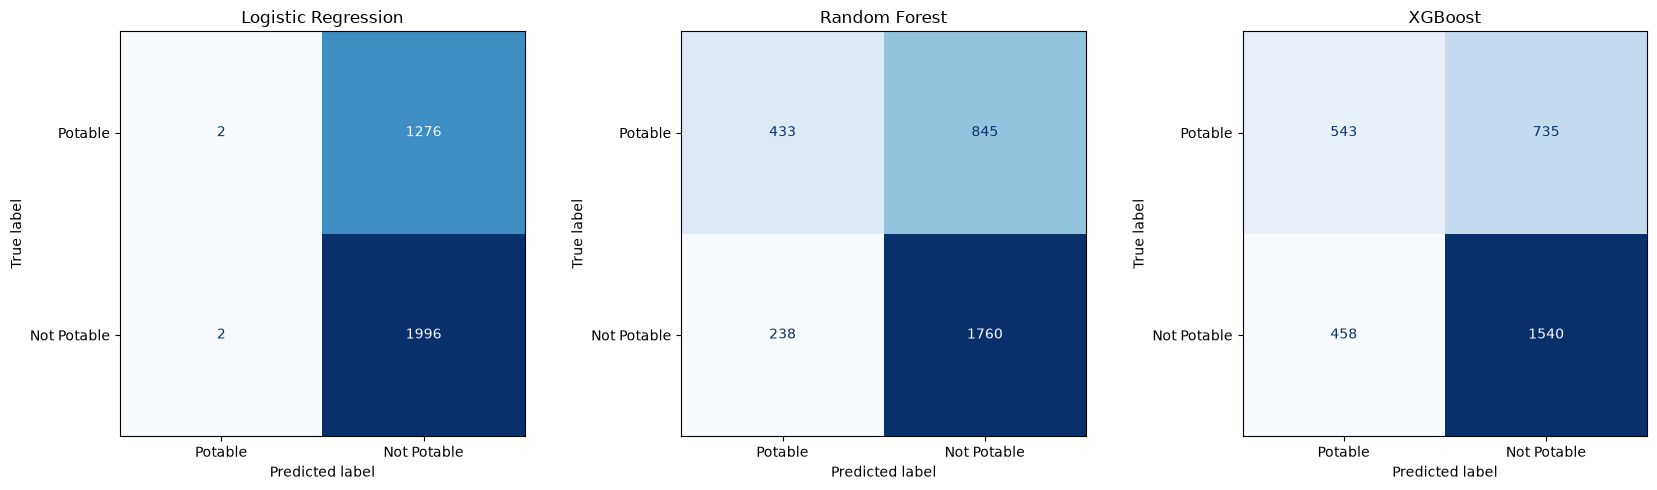

In [12]:


fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (model_name, model_template) in zip(axes, models.items()):

    data_folds = (
        scaled_iterations
        if model_name == "Logistic Regression"
        else processed_folds
    )

    all_true = []
    all_pred = []

    for data in data_folds:
        model = clone(model_template)

        model.fit(data["X_train"], data["y_train"])
        y_pred = model.predict(data["X_val"])

        all_true.extend(data["y_val"])
        all_pred.extend(y_pred)

    # TP = Not Potable (class 0)
    cm = confusion_matrix(
        all_true, all_pred, labels=[1, 0]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Potable", "Not Potable"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()


## hold out method

**Hold-Out evaluation:** Use 70% of the data for training and 30% for testing. Fit imputation and scaling on the training set only, then evaluate the three models on the test set.

In [13]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Separate Features and Target
X = df.drop(columns=["Potability"])
y = df["Potability"]

# Hold-Out: 70% Training, 30% Testing
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print("Training Samples:", len(X_train_h))
print("Testing Samples:", len(X_test_h))

# Fill missing values using TRAIN median only
imputer_h = SimpleImputer(strategy="median")

X_train_h = pd.DataFrame(
    imputer_h.fit_transform(X_train_h),
    columns=X.columns,
    index=X_train_h.index
)

X_test_h = pd.DataFrame(
    imputer_h.transform(X_test_h),
    columns=X.columns,
    index=X_test_h.index
)

print("Train Missing:", X_train_h.isnull().sum().sum())
print("Test Missing:", X_test_h.isnull().sum().sum())

# Feature Scaling for Logistic Regression
scaler_h = StandardScaler()

X_train_scaled_h = scaler_h.fit_transform(X_train_h)
X_test_scaled_h = scaler_h.transform(X_test_h)


Training Samples: 2293
Testing Samples: 983
Train Missing: 0
Test Missing: 0


C:\Users\WINDOWS 11\ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


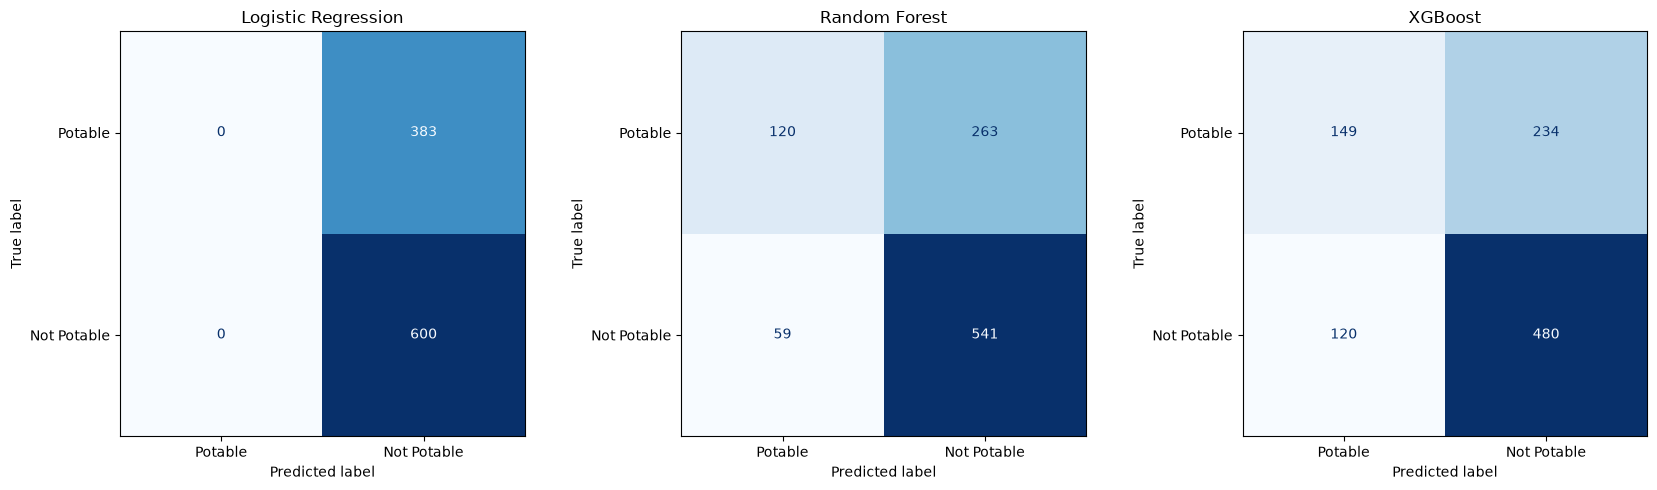

===== HOLD-OUT RESULTS (70/30) =====
                     Accuracy  Precision  Recall     F1  ROC_AUC
Algorithm                                                       
Logistic Regression     61.04       0.00    0.00   0.00    52.96
Random Forest           67.24      67.04   31.33  42.70    65.26
XGBoost                 63.99      55.39   38.90  45.71    62.58


In [14]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

holdout_results = []

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (model_name, model_template) in zip(axes, models.items()):

    model = clone(model_template)

    # Use scaling only for Logistic Regression
    if model_name == "Logistic Regression":
        X_tr = X_train_scaled_h
        X_te = X_test_scaled_h
    else:
        X_tr = X_train_h
        X_te = X_test_h

    model.fit(X_tr, y_train_h)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    holdout_results.append({
        "Algorithm": model_name,
        "Accuracy": accuracy_score(y_test_h, y_pred),
        "Precision": precision_score(y_test_h, y_pred),
        "Recall": recall_score(y_test_h, y_pred),
        "F1": f1_score(y_test_h, y_pred),
        "ROC_AUC": roc_auc_score(y_test_h, y_prob)
    })

    # TP = Not Potable (0)
    cm = confusion_matrix(
        y_test_h, y_pred, labels=[1, 0]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Potable", "Not Potable"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

holdout_df = pd.DataFrame(holdout_results)

print("===== HOLD-OUT RESULTS (70/30) =====")
print((holdout_df.set_index("Algorithm") * 100).round(2))


In [15]:

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

cv_scores = results_df.groupby("Algorithm")[metrics].mean() * 100
holdout_scores = holdout_df.set_index("Algorithm")[metrics] * 100

comparison_table = pd.concat(
    {
        "5-Fold CV": cv_scores,
        "Hold-Out 70/30": holdout_scores
    },
    axis=1
)

print("===== CV vs HOLD-OUT =====")
print(comparison_table.round(2).to_string())


===== CV vs HOLD-OUT =====
                    5-Fold CV                                 Hold-Out 70/30                                
                     Accuracy Precision Recall     F1 ROC_AUC       Accuracy Precision Recall     F1 ROC_AUC
Algorithm                                                                                                   
Logistic Regression     60.99     10.00   0.16   0.31   49.96          61.04      0.00   0.00   0.00   52.96
Random Forest           66.94     64.84  33.88  44.40   68.52          67.24     67.04  31.33  42.70   65.26
XGBoost                 63.58     54.35  42.49  47.66   64.64          63.99     55.39  38.90  45.71   62.58


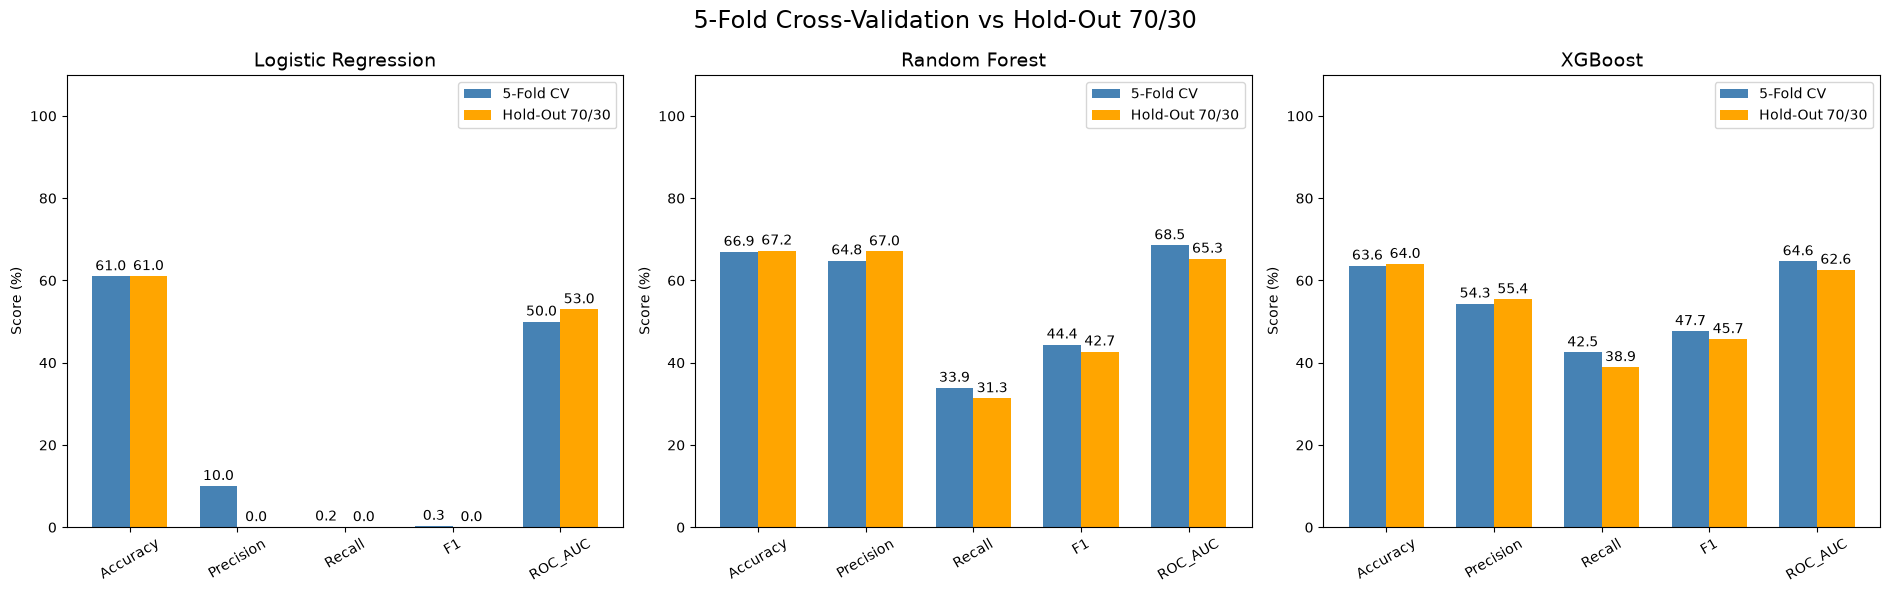

In [16]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

# Average of 5-Fold CV
cv_avg = results_df.groupby("Algorithm")[metrics].mean() * 100

# Hold-Out results
holdout_avg = holdout_df.set_index("Algorithm")[metrics] * 100

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, model_name in zip(axes, models.keys()):

    cv_values = cv_avg.loc[model_name].values
    holdout_values = holdout_avg.loc[model_name].values

    x = np.arange(len(metrics))
    width = 0.35

    bars1 = ax.bar(
        x - width/2, cv_values, width,
        label="5-Fold CV", color="steelblue"
    )

    bars2 = ax.bar(
        x + width/2, holdout_values, width,
        label="Hold-Out 70/30", color="orange"
    )

    ax.set_title(model_name, fontsize=14)
    ax.set_ylabel("Score (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=30)
    ax.set_ylim(0, 110)
    ax.legend()

    ax.bar_label(bars1, fmt="%.1f", padding=2)
    ax.bar_label(bars2, fmt="%.1f", padding=2)

plt.suptitle(
    "5-Fold Cross-Validation vs Hold-Out 70/30",
    fontsize=17
)

plt.tight_layout()
plt.show()


## drop missing value + hold out

**Alternative treatment of missing values:** Delete every row with a missing value instead of filling it. This leaves 2,011 rows out of 3,276; the following results compare this approach with median imputation under Hold-Out evaluation.

In [17]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd
import numpy as np

# Drop rows containing missing values
df_clean = df.dropna().copy()

print("Original Rows:", len(df))
print("Remaining Rows:", len(df_clean))
print("Deleted Rows:", len(df) - len(df_clean))

# Separate features and target
X_clean = df_clean.drop(columns=["Potability"])
y_clean = df_clean["Potability"]

# Hold-Out 70/30
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_clean, y_clean,
    test_size=0.30,
    stratify=y_clean,
    random_state=42
)

print("Training:", len(X_train_d))
print("Testing:", len(X_test_d))

# Scaling for Logistic Regression
scaler_d = StandardScaler()

X_train_scaled_d = scaler_d.fit_transform(X_train_d)
X_test_scaled_d = scaler_d.transform(X_test_d)


Original Rows: 3276
Remaining Rows: 2011
Deleted Rows: 1265
Training: 1407
Testing: 604


In [18]:

drop_results = []

for model_name, model_template in models.items():

    model = clone(model_template)

    if model_name == "Logistic Regression":
        X_tr = X_train_scaled_d
        X_te = X_test_scaled_d
    else:
        X_tr = X_train_d
        X_te = X_test_d

    model.fit(X_tr, y_train_d)

    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    drop_results.append({
        "Algorithm": model_name,
        "Accuracy": accuracy_score(y_test_d, y_pred),
        "Precision": precision_score(y_test_d, y_pred, zero_division=0),
        "Recall": recall_score(y_test_d, y_pred, zero_division=0),
        "F1": f1_score(y_test_d, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test_d, y_prob)
    })

drop_df = pd.DataFrame(drop_results)

print("===== DROP MISSING VALUES - HOLD-OUT 70/30 =====")
print((drop_df.set_index("Algorithm") * 100).round(2))


===== DROP MISSING VALUES - HOLD-OUT 70/30 =====
                     Accuracy  Precision  Recall     F1  ROC_AUC
Algorithm                                                       
Logistic Regression     59.77      57.14    1.64   3.19    49.63
Random Forest           67.38      66.21   39.34  49.36    71.13
XGBoost                 60.26      50.93   44.67  47.60    64.07


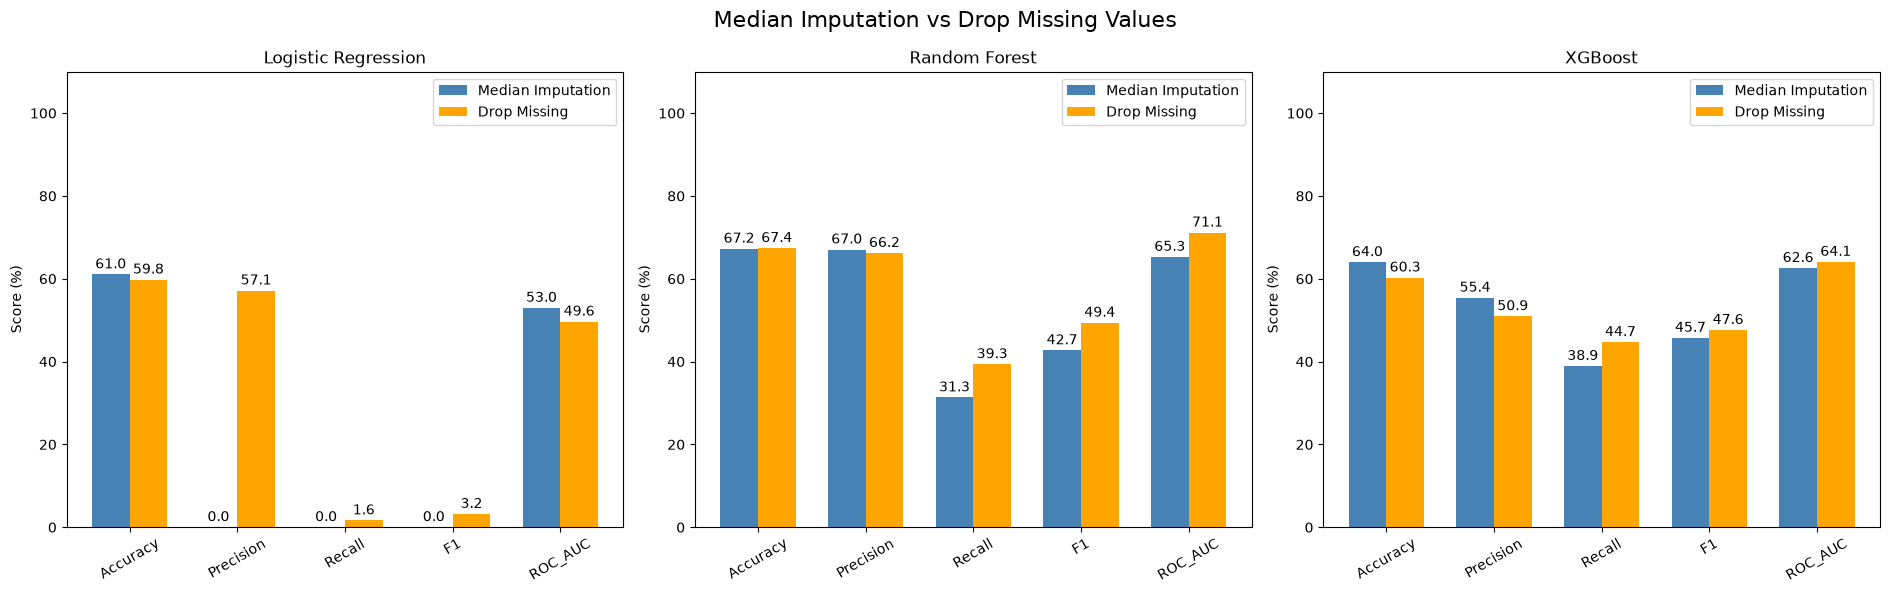

In [19]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

median_scores = holdout_df.set_index("Algorithm")[metrics] * 100
drop_scores = drop_df.set_index("Algorithm")[metrics] * 100

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, model_name in zip(axes, models.keys()):

    x = np.arange(len(metrics))
    width = 0.35

    bars1 = ax.bar(
        x - width/2,
        median_scores.loc[model_name],
        width,
        label="Median Imputation",
        color="steelblue"
    )

    bars2 = ax.bar(
        x + width/2,
        drop_scores.loc[model_name],
        width,
        label="Drop Missing",
        color="orange"
    )

    ax.set_title(model_name)
    ax.set_ylabel("Score (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=30)
    ax.set_ylim(0, 110)
    ax.legend()

    ax.bar_label(bars1, fmt="%.1f", padding=2)
    ax.bar_label(bars2, fmt="%.1f", padding=2)

plt.suptitle(
    "Median Imputation vs Drop Missing Values",
    fontsize=16
)

plt.tight_layout()
plt.show()


## drop missing value + 5 fold cross validation

**5-Fold comparison:** Repeat cross-validation after dropping incomplete rows, then compare Accuracy, Precision, Recall, and F1 with the median-imputation approach.

In [20]:

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

# 1. Remove rows with missing values
df_clean = df.dropna().copy()

X = df_clean.drop(columns=["Potability"])
y = df_clean["Potability"]

print("Original Rows:", len(df))
print("Remaining Rows:", len(df_clean))
print("Deleted Rows:", len(df) - len(df_clean))

# 2. Stratified 5-Fold CV
skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

drop_cv_results = []

# 3. Train all 3 models
for model_name, model_template in models.items():

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X, y), start=1
    ):

        X_train = X.iloc[train_idx].copy()
        X_val = X.iloc[val_idx].copy()
        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Scaling for Logistic Regression
        if model_name == "Logistic Regression":
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_val = scaler.transform(X_val)

        model = clone(model_template)
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)

        train_acc = accuracy_score(y_train, train_pred)
        val_acc = accuracy_score(y_val, val_pred)

        drop_cv_results.append({
            "Algorithm": model_name,
            "Fold": fold,
            "Train Accuracy": train_acc * 100,
            "Validation Accuracy": val_acc * 100,
            "Gap (pp)": (train_acc - val_acc) * 100,
            "Precision": precision_score(
                y_val, val_pred, zero_division=0
            ) * 100,
            "Recall": recall_score(
                y_val, val_pred, zero_division=0
            ) * 100,
            "F1": f1_score(
                y_val, val_pred, zero_division=0
            ) * 100
        })

# 4. Average across 5 folds
drop_cv_df = pd.DataFrame(drop_cv_results)

drop_cv_summary = (
    drop_cv_df.groupby("Algorithm")
    .mean(numeric_only=True)
    .drop(columns=["Fold"])
)

print("===== DROP MISSING + 5-FOLD CV =====")
print(drop_cv_summary.round(2).to_string())


Original Rows: 3276
Remaining Rows: 2011
Deleted Rows: 1265
===== DROP MISSING + 5-FOLD CV =====
                     Train Accuracy  Validation Accuracy  Gap (pp)  Precision  Recall     F1
Algorithm                                                                                   
Logistic Regression           60.06                59.72      0.34      57.27    1.11   2.14
Random Forest                100.00                68.57     31.43      68.41   41.05  51.18
XGBoost                      100.00                65.14     34.86      58.34   47.47  52.31


===== 5-FOLD CV COMPARISON =====
                    Median Imputation                         Drop Missing                        
                             Accuracy Precision Recall     F1     Accuracy Precision Recall     F1
Algorithm                                                                                         
Logistic Regression             60.99     10.00   0.16   0.31        59.72     57.27   1.11   2.14
Random Forest                   66.94     64.84  33.88  44.40        68.57     68.41  41.05  51.18
XGBoost                         63.58     54.35  42.49  47.66        65.14     58.34  47.47  52.31


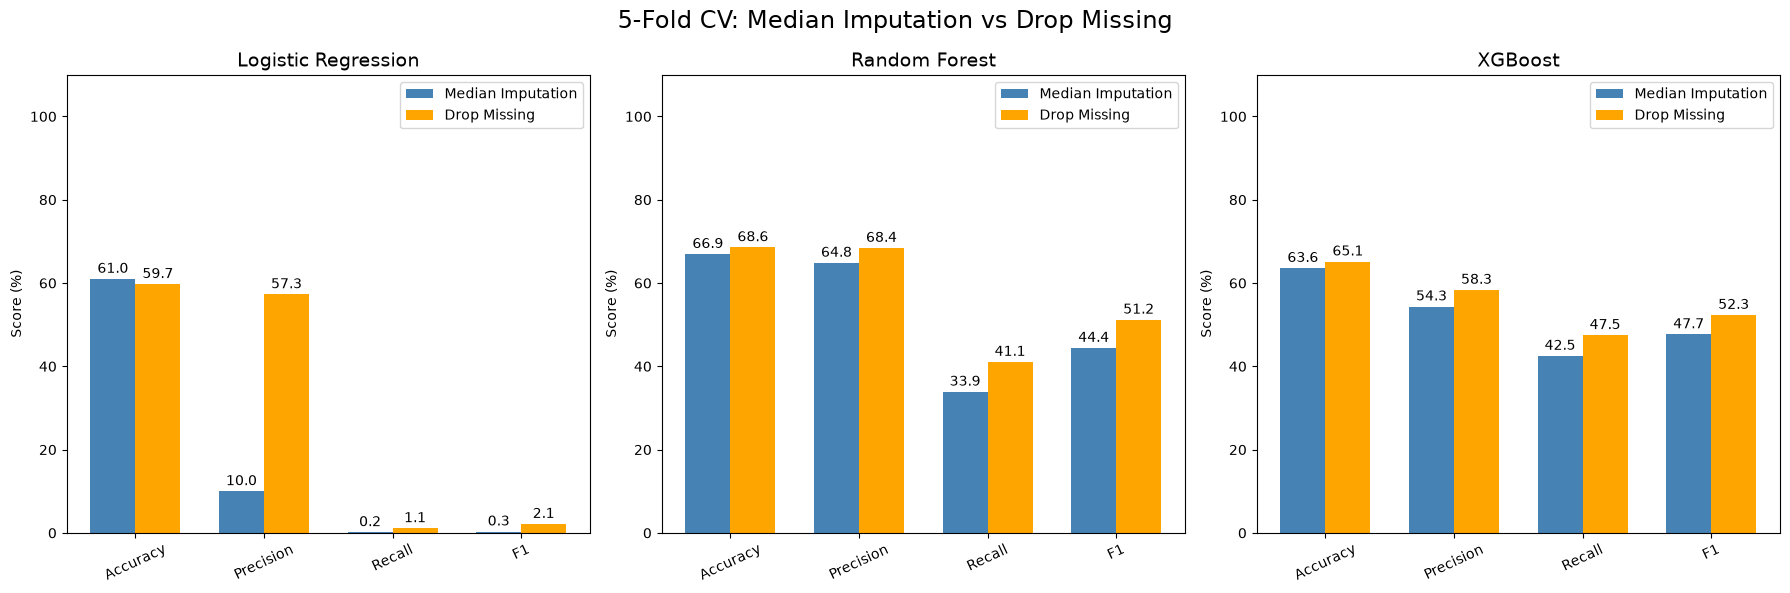

In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1"]

# CV with Median Imputation
median_cv = (
    results_df.groupby("Algorithm")[metrics].mean() * 100
)

# CV after Dropping Missing Rows
drop_cv = drop_cv_df.groupby("Algorithm")[
    ["Validation Accuracy", "Precision", "Recall", "F1"]
].mean()

drop_cv = drop_cv.rename(
    columns={"Validation Accuracy": "Accuracy"}
)

# Comparison Table
comparison = pd.concat(
    {
        "Median Imputation": median_cv,
        "Drop Missing": drop_cv
    },
    axis=1
)

print("===== 5-FOLD CV COMPARISON =====")
print(comparison.round(2).to_string())

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, model_name in zip(axes, models.keys()):

    x = np.arange(len(metrics))
    width = 0.35

    b1 = ax.bar(
        x - width/2,
        median_cv.loc[model_name, metrics],
        width,
        label="Median Imputation",
        color="steelblue"
    )

    b2 = ax.bar(
        x + width/2,
        drop_cv.loc[model_name, metrics],
        width,
        label="Drop Missing",
        color="orange"
    )

    ax.set_title(model_name, fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=25)
    ax.set_ylabel("Score (%)")
    ax.set_ylim(0, 110)
    ax.legend()

    ax.bar_label(b1, fmt="%.1f", padding=2)
    ax.bar_label(b2, fmt="%.1f", padding=2)

plt.suptitle(
    "5-Fold CV: Median Imputation vs Drop Missing",
    fontsize=17
)

plt.tight_layout()
plt.show()


## check overfitting | underfitting 

**Overfitting check:** Compare training accuracy with validation/testing accuracy. A large positive gap suggests that a model fits the training data much better than unseen data.

===== OVERFITTING CHECK =====
           Method     Evaluation               Model  Train Accuracy  Test Accuracy  Gap (pp)
Median Imputation Hold-Out 70/30 Logistic Regression           60.97          61.04     -0.07
Median Imputation Hold-Out 70/30       Random Forest          100.00          67.24     32.76
Median Imputation Hold-Out 70/30             XGBoost          100.00          63.99     36.01
Median Imputation      5-Fold CV Logistic Regression           61.12          60.99      0.13
Median Imputation      5-Fold CV       Random Forest          100.00          66.94     33.06
Median Imputation      5-Fold CV             XGBoost          100.00          63.58     36.42
     Drop Missing Hold-Out 70/30 Logistic Regression           60.63          59.77      0.86
     Drop Missing Hold-Out 70/30       Random Forest          100.00          67.38     32.62
     Drop Missing Hold-Out 70/30             XGBoost          100.00          60.26     39.74
     Drop Missing      5-Fold 

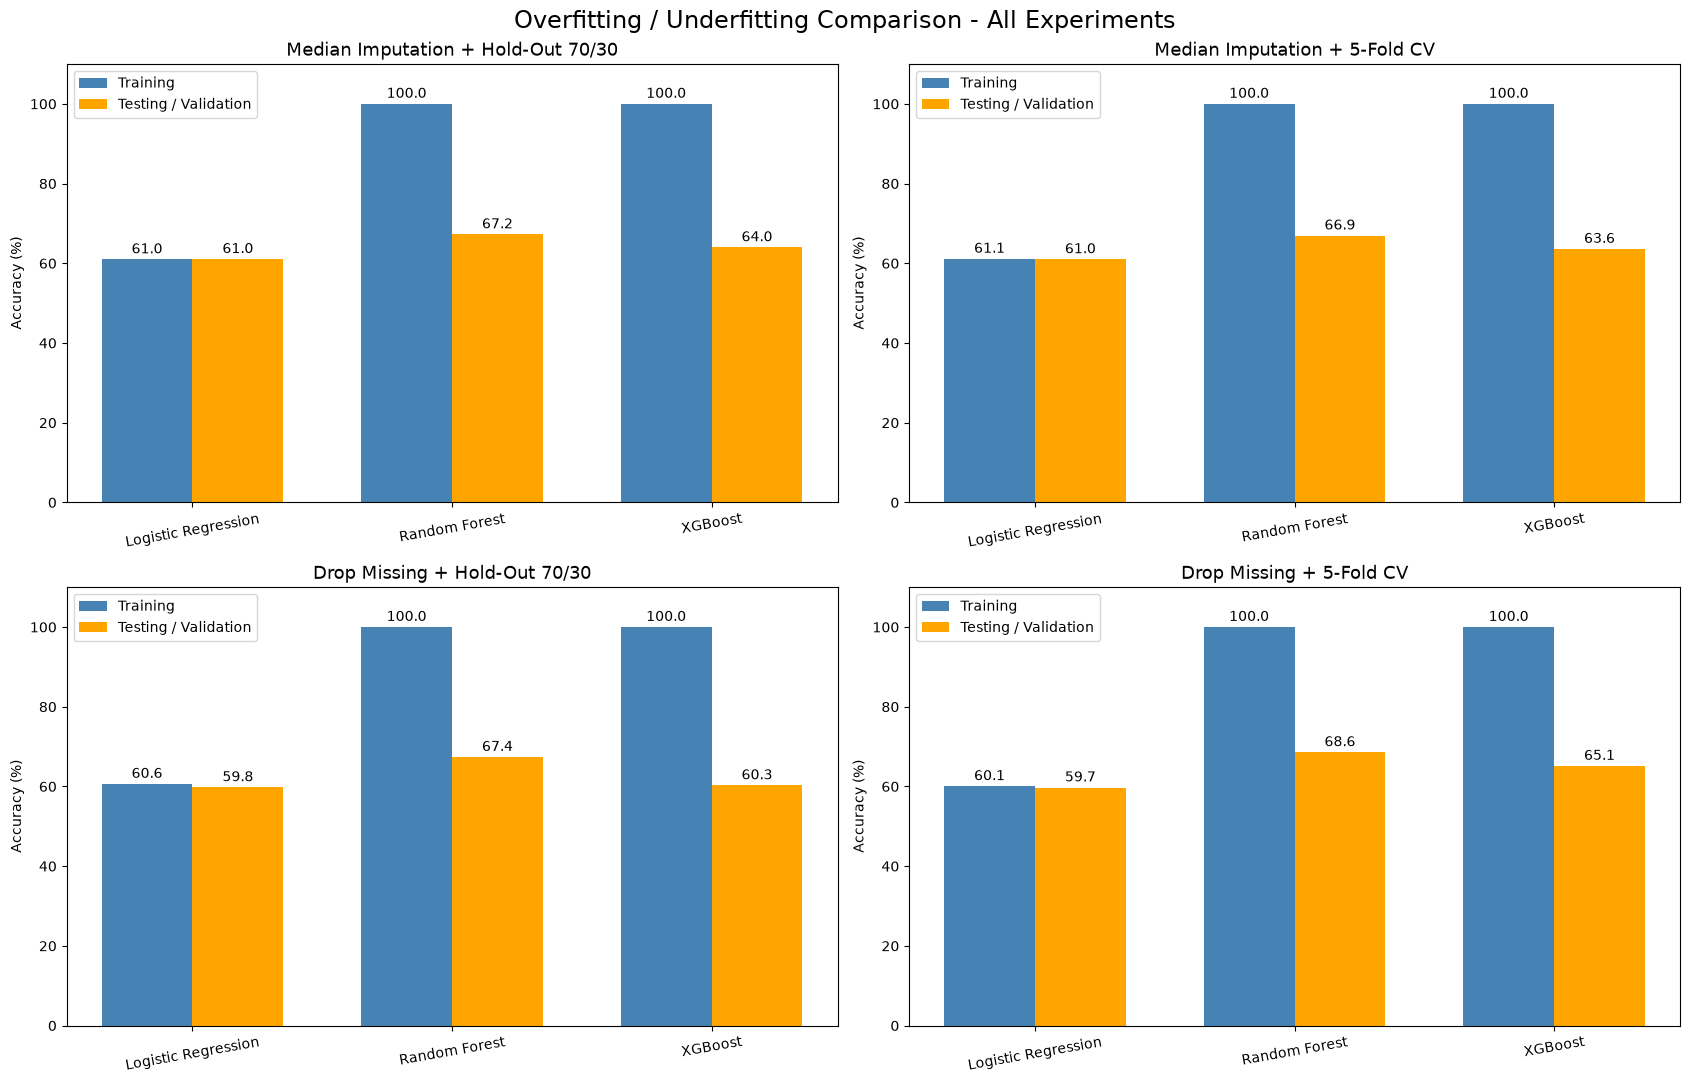

In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate
)
from sklearn.metrics import accuracy_score

results = []

# 4 Experiments
for missing_method in ["Median Imputation", "Drop Missing"]:

    if missing_method == "Drop Missing":
        data = df.dropna().copy()
    else:
        data = df.copy()

    X = data.drop(columns=["Potability"])
    y = data["Potability"]

    for evaluation in ["Hold-Out 70/30", "5-Fold CV"]:

        for model_name, model_template in models.items():

            steps = []

            # Median Imputation
            if missing_method == "Median Imputation":
                steps.append(
                    ("imputer", SimpleImputer(strategy="median"))
                )

            # Scaling for Logistic Regression
            if model_name == "Logistic Regression":
                steps.append(("scaler", StandardScaler()))

            steps.append(("model", clone(model_template)))

            pipeline = Pipeline(steps)

            # HOLD-OUT
            if evaluation == "Hold-Out 70/30":

                X_train, X_test, y_train, y_test = train_test_split(
                    X, y,
                    test_size=0.30,
                    stratify=y,
                    random_state=42
                )

                pipeline.fit(X_train, y_train)

                train_acc = accuracy_score(
                    y_train, pipeline.predict(X_train)
                ) * 100

                test_acc = accuracy_score(
                    y_test, pipeline.predict(X_test)
                ) * 100

            # 5-FOLD CV
            else:

                cv = StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                )

                scores = cross_validate(
                    pipeline,
                    X,
                    y,
                    cv=cv,
                    scoring="accuracy",
                    return_train_score=True
                )

                train_acc = scores["train_score"].mean() * 100
                test_acc = scores["test_score"].mean() * 100

            results.append({
                "Method": missing_method,
                "Evaluation": evaluation,
                "Model": model_name,
                "Train Accuracy": train_acc,
                "Test Accuracy": test_acc,
                "Gap (pp)": train_acc - test_acc
            })

# Results Table
overfit_df = pd.DataFrame(results)

print("===== OVERFITTING CHECK =====")
print(overfit_df.round(2).to_string(index=False))


# ============================================
# VISUALIZATION
# ============================================

experiments = [
    ("Median Imputation", "Hold-Out 70/30"),
    ("Median Imputation", "5-Fold CV"),
    ("Drop Missing", "Hold-Out 70/30"),
    ("Drop Missing", "5-Fold CV")
]

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

for ax, (method, evaluation) in zip(axes.flat, experiments):

    subset = overfit_df[
        (overfit_df["Method"] == method) &
        (overfit_df["Evaluation"] == evaluation)
    ]

    x = np.arange(len(subset))
    width = 0.35

    b1 = ax.bar(
        x - width/2,
        subset["Train Accuracy"],
        width,
        label="Training",
        color="steelblue"
    )

    b2 = ax.bar(
        x + width/2,
        subset["Test Accuracy"],
        width,
        label="Testing / Validation",
        color="orange"
    )

    ax.set_title(f"{method} + {evaluation}", fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(subset["Model"], rotation=10)
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 110)
    ax.legend()

    ax.bar_label(b1, fmt="%.1f", padding=2)
    ax.bar_label(b2, fmt="%.1f", padding=2)

plt.suptitle(
    "Overfitting / Underfitting Comparison - All Experiments",
    fontsize=17
)

plt.tight_layout()
plt.show()


## hyperparameter tuning | random forest 

**Random Forest tuning:** Use `GridSearchCV` inside each training fold to select hyperparameters. The stored results show that the average train–validation gap decreases from **33.03** to **9.85 percentage points**, while validation accuracy changes from **66.97%** to **65.72%**. Tuning reduces overfitting here but does not improve validation accuracy.

Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed

===== RANDOM FOREST 5-FOLD CV =====
               Train Accuracy  Validation Accuracy    Gap
Model                                                    
Before Tuning          100.00                66.97  33.03
After Tuning            75.57                65.72   9.85


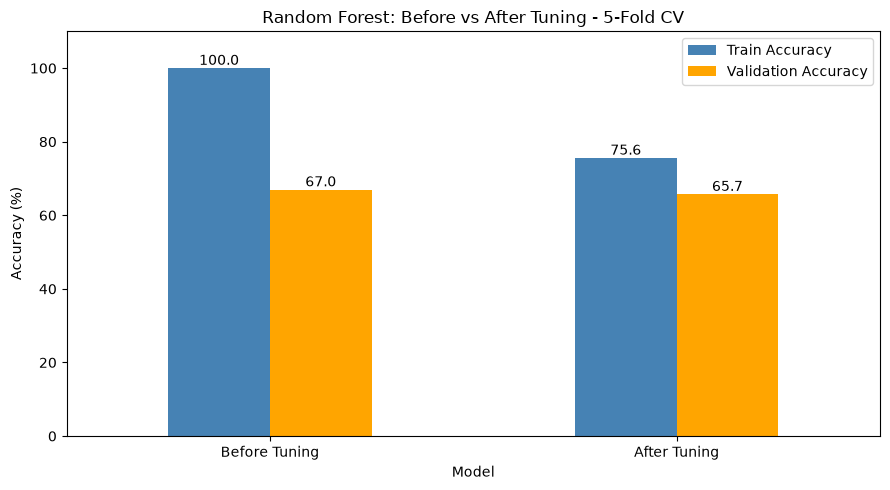

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    StratifiedKFold, GridSearchCV
)
from sklearn.metrics import accuracy_score

X = df.drop(columns=["Potability"])
y = df["Potability"]

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

param_grid = {
    "rf__max_depth": [5, 10],
    "rf__min_samples_split": [2, 10],
    "rf__min_samples_leaf": [2, 5]
}

results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y), 1):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    baseline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        ))
    ])

    # Before Tuning
    baseline.fit(X_train, y_train)

    # After Tuning - inside training fold only
    tuned_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        ))
    ])

    grid = GridSearchCV(
        tuned_pipeline,
        param_grid,
        cv=3,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    for name, model in [
        ("Before Tuning", baseline),
        ("After Tuning", grid.best_estimator_)
    ]:
        train_acc = accuracy_score(
            y_train, model.predict(X_train)
        ) * 100

        val_acc = accuracy_score(
            y_val, model.predict(X_val)
        ) * 100

        results.append({
            "Fold": fold,
            "Model": name,
            "Train Accuracy": train_acc,
            "Validation Accuracy": val_acc,
            "Gap": train_acc - val_acc
        })

    print(f"Fold {fold}/5 completed")

# Average results
result_df = pd.DataFrame(results)

summary = result_df.groupby("Model")[
    ["Train Accuracy", "Validation Accuracy", "Gap"]
].mean()

summary = summary.reindex([
    "Before Tuning", "After Tuning"
])

print("\n===== RANDOM FOREST 5-FOLD CV =====")
print(summary.round(2))

# Visualization
ax = summary[[
    "Train Accuracy", "Validation Accuracy"
]].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange"],
    rot=0
)

ax.set_title("Random Forest: Before vs After Tuning - 5-Fold CV")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 110)
ax.bar_label(ax.containers[0], fmt="%.1f")
ax.bar_label(ax.containers[1], fmt="%.1f")

plt.tight_layout()
plt.show()
